# Q-Learning tabular — CartPole-v1
**Implementación, experimentos y resultados finales · Tier 1**

Este notebook resume el trabajo desarrollado y conserva las funciones principales del algoritmo. **Las gráficas finales reproducen resultados previamente obtenidos**, no ejecutan nuevamente los entrenamientos extensos. El notebook original `Q_Learning_CartPole.ipynb` conserva el desarrollo y las salidas experimentales completas.

**Ruta de exposición:** discretización → tabla Q → selección de acciones → aprendizaje → experimentos → configuración final.

### Part 1 - Setup and Discretization
**¿Qué hicimos?** CartPole entrega cuatro observaciones continuas: posición, velocidad, ángulo y velocidad angular. Las convertimos en índices usando intervalos para poder consultar una tabla Q. El agente dispone de dos acciones: izquierda (0) y derecha (1).

In [2]:
# ============================================================
# PART 1 - CONFIGURACIÓN Y DISCRETIZACIÓN
# ============================================================

import numpy as np
import gymnasium as gym
import matplotlib.pyplot as plt
import time

NUM_ACTIONS = 2
ALPHA = 0.1
GAMMA = 0.99

# Rangos de la configuración seleccionada (Ajuste A)
MINIMOS = np.array([-2.4, -2.0, -0.2095, -2.5])
MAXIMOS = np.array([2.4, 2.0, 0.2095, 2.5])

N_BINS = 10
SEMILLAS_SELECCION = [42, 123, 456]
SEMILLAS_VALIDACION = [7, 21, 99]
PASOS_SELECCIONADOS = 300_000

# Convertir las cuatro observaciones en cuatro índices discretos
def discretizar_estado(estado, n_bins):
    indices = []
    for i in range(4):
        limites = np.linspace(MINIMOS[i], MAXIMOS[i], n_bins + 1)
        indice = np.digitize(estado[i], limites[1:-1])
        indices.append(int(indice))
    return tuple(indices)

# Ejemplo de discretización, sin entrenar
estado_ejemplo = np.array([0.0274, -0.0061, 0.0359, 0.0197])
print("Estado continuo:", estado_ejemplo)
print("Estado discreto:", discretizar_estado(estado_ejemplo, N_BINS))

Estado continuo: [ 0.0274 -0.0061  0.0359  0.0197]
Estado discreto: (5, 4, 5, 5)


### Part 2 - Q-Table, Epsilon-Greedy and Q-Learning Update
**¿Qué implementamos?** La tabla guarda un valor por combinación de estado y acción. `epsilon_greedy()` decide entre explorar y elegir una acción con el mayor Q. `update_q()` corrige el Q después de observar la recompensa y el siguiente estado.

- **Alpha:** cuánto corregimos el valor Q en cada experiencia.
- **Gamma:** cuánto peso damos a la recompensa futura estimada.
- **Epsilon:** probabilidad de elegir una acción aleatoria durante el entrenamiento.

In [3]:
# ============================================================
# PART 2 - TABLA Q Y FUNCIONES PRINCIPALES
# ============================================================

# Cada una de las cuatro variables tiene n_bins intervalos;
# la última dimensión corresponde a las dos acciones.
Q = np.zeros((N_BINS, N_BINS, N_BINS, N_BINS, NUM_ACTIONS))


def epsilon_greedy(Q, state, epsilon, rng):
    # Explorar: seleccionar una acción aleatoria
    if rng.random() < epsilon:
        return int(rng.integers(NUM_ACTIONS))

    # Explotar: consultar los valores Q del estado actual
    q_values = Q[state]
    max_q = np.max(q_values)

    # Resolver los empates aleatoriamente
    mejores_acciones = np.flatnonzero(np.isclose(q_values, max_q))
    return int(rng.choice(mejores_acciones))


def update_q(Q, state, action, reward, next_state, terminated,
             alpha, gamma):
    # Consultar el valor Q que vamos a corregir
    q_actual = Q[state + (action,)]

    # Si terminó por fallo, no se añade valor futuro
    if terminated:
        objetivo = reward
    else:
        mejor_q_siguiente = np.max(Q[next_state])
        objetivo = reward + gamma * mejor_q_siguiente

    # Aplicar la corrección a la acción realizada
    error_td = objetivo - q_actual
    Q[state + (action,)] += alpha * error_td
    return error_td

print("Forma de la tabla Q:", Q.shape)
print("Valores Q totales:", Q.size)

Forma de la tabla Q: (10, 10, 10, 10, 2)
Valores Q totales: 20000


### Part 3 - Training and Evaluation
**¿Cómo se conectan las funciones?** El agente reinicia CartPole, discretiza el estado, selecciona una acción, recibe recompensa y actualiza su tabla. El entrenamiento se controla por **pasos**, no por número de episodios. En evaluación usamos `epsilon=0` y **no modificamos Q**.

La función de entrenamiento está disponible para una demostración o para reproducir pruebas, pero **no se ejecuta automáticamente** en este notebook de exposición.

In [4]:
# ============================================================
# PART 3 - EVALUACIÓN SIN EXPLORACIÓN
# ============================================================

def evaluate_q_learning(Q, n_bins, seed=20_000, episodes=100):
    env = gym.make("CartPole-v1")
    rng = np.random.default_rng(seed)
    recompensas = []

    try:
        for episodio in range(episodes):
            observacion, _ = env.reset(seed=seed + episodio)
            estado = discretizar_estado(observacion, n_bins)
            recompensa_total = 0.0
            terminado = False

            while not terminado:
                # Epsilon = 0: utilizar los Q aprendidos
                accion = epsilon_greedy(Q, estado, 0.0, rng)
                siguiente_obs, recompensa, terminated, truncated, _ = env.step(accion)
                estado = discretizar_estado(siguiente_obs, n_bins)
                recompensa_total += recompensa
                terminado = terminated or truncated

            recompensas.append(recompensa_total)
    finally:
        env.close()

    return recompensas, float(np.mean(recompensas)), float(np.std(recompensas))

In [5]:
# ============================================================
# PART 3 - ENTRENAMIENTO POR PASOS CON EPSILON DECRECIENTE
# ============================================================

def train_q_learning(seed, n_bins=10, total_steps=300_000,
                     alpha=0.1, gamma=0.99,
                     eval_interval=10_000,
                     eval_episodes=10):
    rng = np.random.default_rng(seed)
    env = gym.make("CartPole-v1")
    Q = np.zeros((n_bins, n_bins, n_bins, n_bins, NUM_ACTIONS))
    historial = []
    pasos = 0
    episodio = 0
    inicio = time.perf_counter()

    try:
        while pasos < total_steps:
            observacion, _ = env.reset(seed=seed + episodio)
            estado = discretizar_estado(observacion, n_bins)
            terminado = False

            while not terminado and pasos < total_steps:
                # Explorar mucho al inicio y reducir epsilon hasta 0.05
                progreso = min(pasos / 150_000, 1.0)
                epsilon = 1.0 - (1.0 - 0.05) * progreso

                # Elegir acción, ejecutar y actualizar Q
                accion = epsilon_greedy(Q, estado, epsilon, rng)
                siguiente_obs, recompensa, terminated, truncated, _ = env.step(accion)
                siguiente_estado = discretizar_estado(siguiente_obs, n_bins)
                update_q(Q, estado, accion, recompensa, siguiente_estado,
                         terminated, alpha, gamma)

                estado = siguiente_estado
                terminado = terminated or truncated
                pasos += 1

                # Evaluaciones periódicas sin modificar la tabla Q
                if pasos % eval_interval == 0:
                    _, media, desv = evaluate_q_learning(
                        Q, n_bins, seed=10_000, episodes=eval_episodes
                    )
                    historial.append((pasos, media, desv))

            episodio += 1
    finally:
        env.close()

    # Evaluación final sobre 100 episodios
    _, media_final, desv_final = evaluate_q_learning(
        Q, n_bins, seed=20_000, episodes=100
    )
    tiempo = time.perf_counter() - inicio
    return Q, historial, media_final, desv_final, tiempo

# Para demostrar el entrenamiento sin repetir las pruebas extensas,
# se puede llamar manualmente a la función con pocos pasos.
# Ejemplo opcional: Q_demo, curva, media, desv, t = train_q_learning(42, total_steps=2000)

### Part 4 - Experiments: What We Tested
**Pregunta de investigación:** ¿Qué decisiones mejoraron Q-learning? Cada comparación cambia un aspecto y mantiene el resto de condiciones del experimento correspondiente. Los valores siguientes son **resultados históricos registrados**, con tres semillas y evaluaciones finales de 100 episodios por entrenamiento.

**Importante:** los primeros experimentos utilizaron **200.000 pasos**. Por tanto, sus medias describen etapas diferentes de ajuste, no resultados obtenidos todos bajo una configuración idéntica.

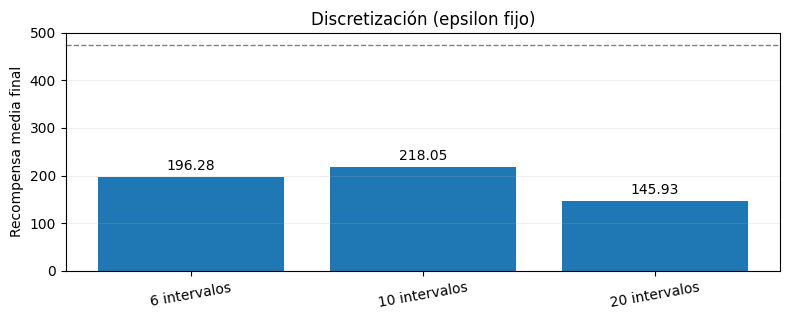

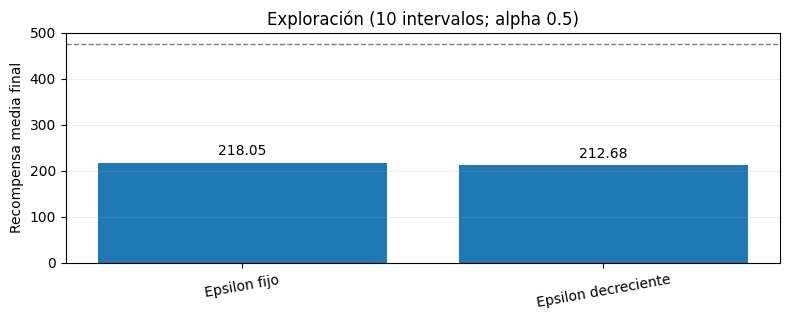

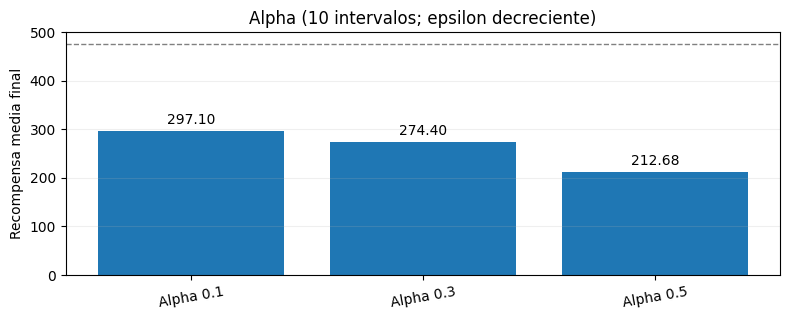

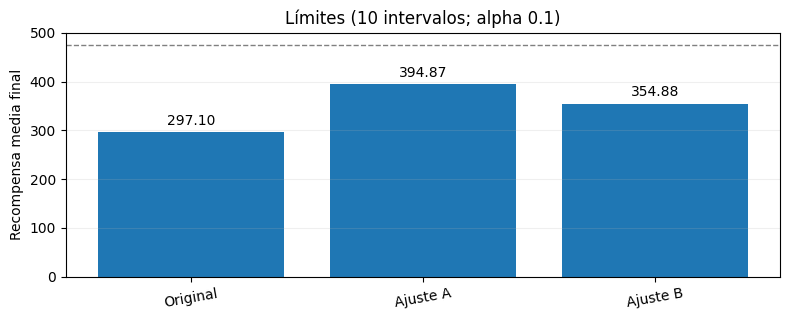

In [6]:
# ============================================================
# PART 4 - RESULTADOS HISTÓRICOS DE LOS EXPERIMENTOS
# ============================================================

# Recompensas finales promedio entre tres semillas.
# Datos registrados durante el desarrollo; no vuelven a entrenarse.
experimentos = {
    "Discretización (epsilon fijo)": {
        "6 intervalos": 196.28,
        "10 intervalos": 218.05,
        "20 intervalos": 145.93,
    },
    "Exploración (10 intervalos; alpha 0.5)": {
        "Epsilon fijo": 218.05,
        "Epsilon decreciente": 212.68,
    },
    "Alpha (10 intervalos; epsilon decreciente)": {
        "Alpha 0.1": 297.10,
        "Alpha 0.3": 274.40,
        "Alpha 0.5": 212.68,
    },
    "Límites (10 intervalos; alpha 0.1)": {
        "Original": 297.10,
        "Ajuste A": 394.87,
        "Ajuste B": 354.88,
    },
}

# Mostrar las cuatro comparaciones en el mismo notebook
for titulo, resultados in experimentos.items():
    etiquetas = list(resultados)
    valores = list(resultados.values())

    fig, ax = plt.subplots(figsize=(8, 3.3))
    barras = ax.bar(etiquetas, valores)
    ax.bar_label(barras, fmt="%.2f", padding=3)
    ax.set_title(titulo)
    ax.set_ylabel("Recompensa media final")
    ax.set_ylim(0, 500)
    ax.axhline(475, linestyle="--", color="gray", linewidth=1)
    ax.tick_params(axis="x", labelrotation=10)
    ax.grid(axis="y", alpha=0.2)
    fig.tight_layout()
    plt.show()

**Lectura para la exposición:**

1. **Discretización:** con 200.000 pasos y epsilon fijo, 10 intervalos dio el mayor promedio (218.05).
2. **Epsilon:** cambiar a exploración decreciente no mejoró por sí solo el promedio (212.68 frente a 218.05), pero redujo la variación entre semillas en esa prueba.
3. **Alpha:** con epsilon decreciente, alpha 0.1 aumentó el promedio a 297.10; no obstante, mostró variabilidad alta.
4. **Límites:** acotar los intervalos de velocidad en el **Ajuste A** elevó el promedio a 394.87 a los 200.000 pasos.

*Gamma se mantuvo en 0.99; no se realizó una comparación de distintos gamma.*

### Part 5 - Final Training Budget and Independent Validation
**¿Por qué 300.000 pasos?** Con Ajuste A, alpha 0.1 y 10 intervalos evaluamos las tablas Q a los 200.000, 300.000 y 400.000 pasos. La mejor evaluación entre esos puntos fue a los 300.000. Después comprobamos la configuración con **tres semillas nuevas**, que no se habían usado en el ajuste.

Las cifras son medias de **100 episodios de evaluación por semilla** con epsilon igual a cero.

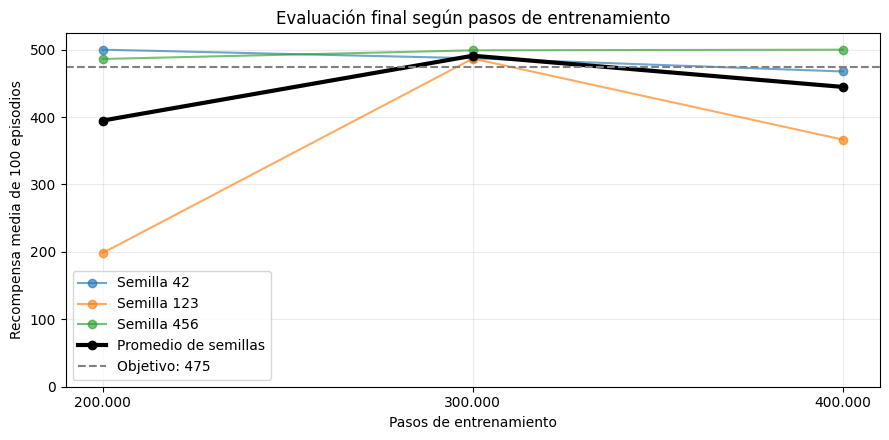

PASOS     PROMEDIO  DESV. ENTRE SEMILLAS  SEMILLAS >= 475
200000     394.87               139.05  2/3
300000     491.05                 5.65  3/3
400000     444.74                56.84  1/3


In [7]:
# ============================================================
# PART 5 - RESULTADOS POR SEMILLA Y PRESUPUESTO
# ============================================================

pasos = np.array([200_000, 300_000, 400_000])
resultados_por_semilla = {
    42: [500.00, 487.28, 467.67],
    123: [198.38, 486.84, 366.55],
    456: [486.23, 499.04, 500.00],
}

matriz = np.array(list(resultados_por_semilla.values()))
medias = matriz.mean(axis=0)
desviaciones = matriz.std(axis=0)

fig, ax = plt.subplots(figsize=(9, 4.5))
for semilla, recompensas in resultados_por_semilla.items():
    ax.plot(pasos, recompensas, marker="o", alpha=0.65,
            label=f"Semilla {semilla}")
ax.plot(pasos, medias, marker="o", linewidth=3, color="black",
        label="Promedio de semillas")
ax.axhline(475, linestyle="--", color="gray", label="Objetivo: 475")
ax.set_title("Evaluación final según pasos de entrenamiento")
ax.set_xlabel("Pasos de entrenamiento")
ax.set_ylabel("Recompensa media de 100 episodios")
ax.set_xticks(pasos, ["200.000", "300.000", "400.000"])
ax.set_ylim(0, 525)
ax.legend()
ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()

print("PASOS     PROMEDIO  DESV. ENTRE SEMILLAS  SEMILLAS >= 475")
for j, paso in enumerate(pasos):
    print(f"{paso:<9} {medias[j]:>7.2f}  {desviaciones[j]:>19.2f}  "
          f"{np.sum(matriz[:, j] >= 475)}/3")

VALIDACIÓN INDEPENDIENTE - 300.000 PASOS
Semilla 7: 500.00
Semilla 21: 474.45
Semilla 99: 486.15

Selección: media 491.05, desviación 5.65, semillas exitosas 3/3
Validación: media 486.87, desviación 10.44, semillas exitosas 2/3


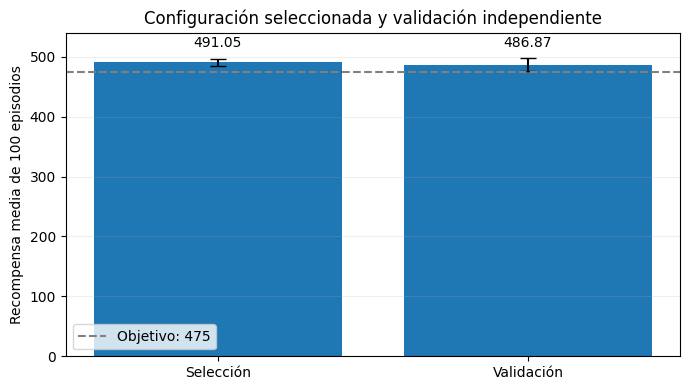

In [8]:
# ============================================================
# PART 5 - VALIDACIÓN CON SEMILLAS NUEVAS
# ============================================================

seleccion = np.array([487.28, 486.84, 499.04])
validacion = {7: 500.00, 21: 474.45, 99: 486.15}
valores_validacion = np.array(list(validacion.values()))

print("VALIDACIÓN INDEPENDIENTE - 300.000 PASOS")
for semilla, recompensa in validacion.items():
    print(f"Semilla {semilla}: {recompensa:.2f}")

print(f"\nSelección: media {seleccion.mean():.2f}, "
      f"desviación {seleccion.std():.2f}, "
      f"semillas exitosas {np.sum(seleccion >= 475)}/3")
print(f"Validación: media {valores_validacion.mean():.2f}, "
      f"desviación {valores_validacion.std():.2f}, "
      f"semillas exitosas {np.sum(valores_validacion >= 475)}/3")

fig, ax = plt.subplots(figsize=(7, 4))
barras = ax.bar(["Selección", "Validación"],
                [seleccion.mean(), valores_validacion.mean()],
                yerr=[seleccion.std(), valores_validacion.std()], capsize=6)
ax.bar_label(barras, fmt="%.2f", padding=6)
ax.axhline(475, linestyle="--", color="gray", label="Objetivo: 475")
ax.set_ylim(0, 540)
ax.set_ylabel("Recompensa media de 100 episodios")
ax.set_title("Configuración seleccionada y validación independiente")
ax.legend()
ax.grid(axis="y", alpha=0.2)
fig.tight_layout()
plt.show()

### Part 6 - Selected Configuration and Conclusions

| Elemento | Configuración seleccionada |
|---|---|
| Entorno | CartPole-v1 |
| Algoritmo | Q-learning tabular |
| Discretización | 10 intervalos por variable |
| Límites mínimos | `[-2.4, -2.0, -0.2095, -2.5]` |
| Límites máximos | `[2.4, 2.0, 0.2095, 2.5]` |
| Alpha | 0.1 |
| Gamma | 0.99 (fijo en las pruebas) |
| Epsilon | Decreciente, desde 1.0 hasta 0.05 en 150.000 pasos |
| Presupuesto elegido | 300.000 pasos |
| Evaluación final | 100 episodios, epsilon = 0 |

**Conclusiones para defender:**

- Implementamos las funciones de discretización, selección epsilon-greedy, actualización Q, entrenamiento y evaluación.
- Comparamos los tres niveles obligatorios de discretización (6, 10 y 20).
- En las pruebas, **alpha 0.1** y el **Ajuste A** mejoraron la recompensa media frente a los ajustes iniciales.
- A los **300.000 pasos** obtuvimos una media de **491.05**, con **3/3 semillas ≥ 475**. A los 400.000 pasos la media bajó: más entrenamiento no garantizó una mejora continua.
- Con semillas nuevas, la media fue **486.87**, y **2/3 semillas** superaron individualmente 475. La tercera obtuvo 474.45; no debemos presentar una garantía de éxito universal.
- El presupuesto de 300.000 pasos se eligió **después de analizar los resultados**; para la comparación con DQN habrá que utilizar el mismo presupuesto, evaluaciones y condiciones.

**Nota metodológica:** las gráficas de resultados registran medias y desviaciones reportadas en el desarrollo. No reemplazan el historial completo por paso de cada entrenamiento ni los modelos Q entrenados. El notebook original conserva el proceso experimental que dio lugar a estos resúmenes.